# Bank Marketing Campaign: Logistic Regression

## Project Objective

The objective of this project is to build a Logistic Regression model to predict whether a bank customer will subscribe to a term deposit based on customer characteristics, campaign information, and previous contact history.

The target variable is `y`, where:

- `yes` → Customer subscribed to a term deposit
- `no` → Customer did not subscribe

 A term deposit is a type of bank deposit where a person deposits money for a fixed period, such as 6 months or 1 year, and earns interest on it. Usually, the money is kept in the bank until the agreed period ends.

In this project, the bank contacts customers through marketing campaigns to encourage them to open a term deposit. The goal is to predict whether a customer will subscribe (yes) or not (no).

### Importing Required Libraries

In [1]:
# Data Handling
import pandas as pd
import numpy as np

# Visualization / EDA
import matplotlib.pyplot as plt
import seaborn as sns

# Statistical Analysis
from scipy import stats

# Preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Logistic Regression
from sklearn.linear_model import LogisticRegression

# Model Evaluation
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    roc_curve,
    precision_score,
    recall_score,
    f1_score
)

# Ignore warnings
import warnings
warnings.filterwarnings("ignore")

### Load the Dataset

In [2]:
df = pd.read_csv("bank-additional-full.csv", sep=";")
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


### Data Dictionary

The Bank Marketing dataset contains information about customers, their contact with the bank, previous contacts, and the conditions when the bank contacted them.

| Column | Simple Explanation |
|---|---|
| `age` | The customer's age. |
| `job` | The customer's type of job or occupation. |
| `marital` | The customer's marital status, such as married, single, or divorced. |
| `education` | The customer's education level, such as high school or university degree. |
| `default` | Whether the customer has failed to pay a previous credit or loan. |
| `housing` | Whether the customer has a housing loan. |
| `loan` | Whether the customer has a personal loan. |
| `contact` | How the bank contacted the customer, such as by phone or mobile. |
| `month` | The month when the bank contacted the customer. |
| `day_of_week` | The day when the bank contacted the customer, such as Monday or Friday. |
| `duration` | How long the phone call lasted, measured in seconds. |
| `campaign` | How many times the bank contacted this customer during this round of calls. |
| `pdays` | How many days had passed since the bank last contacted this customer in an earlier round. A value of `-1` means the customer had not been contacted before. |
| `previous` | How many times the bank had contacted this customer before the current round of calls. |
| `poutcome` | What happened when the bank contacted this customer previously, such as whether the customer subscribed or not. |
| `emp.var.rate` | Shows the employment situation when the customer was contacted. |
| `cons.price.idx` | Shows the general prices of goods and services when the customer was contacted. |
| `cons.conf.idx` | Shows how confident people were about their financial situation when the customer was contacted. |
| `euribor3m` | Shows the interest-rate situation when the customer was contacted. |
| `nr.employed` | Shows the overall number of employed people at that time. |
| `y` | **Target variable:** whether the customer subscribed to the bank's term deposit (`yes` or `no`). |

### Literature Review & Hypothesis

- **Age may affect whether a customer chooses to open a term deposit. Customers of different age groups may have different saving habits.**

- *Hypothesis:* **Subscription rates may differ between age groups.**

- *Reference:* **Moro et al. (2014).**

- **A customer’s job and education level may affect their decision to save money in a bank. People with different jobs or education levels may make different financial decisions.**

- *Hypothesis:* **Subscription rates may differ according to job and education level.**

- *Reference:* **Nechita et al. (2024).**

- **The month in which a customer is contacted may affect the success of a marketing campaign. Some months may have more successful subscriptions than others.**

- *Hypothesis:* **Subscription rates may differ from month to month.**

- *Reference:* **Moro et al. (2014).**

- **The bank may contact a customer more than once to offer a term deposit. However, contacting someone many times does not always mean they will subscribe.**

- *Hypothesis:* **The number of contacts may be related to subscription success.**

- *Reference:* **Moro et al. (2014).**

- **A customer who agreed to a bank offer in the past may be more likely to agree to another offer. Previous campaign results may help the bank understand customer interest.**

- *Hypothesis:* **Customers’ previous campaign results may be related to subscription success.**

- *Reference:* **Nechita et al. (2024).**

- **Economic conditions, such as employment rates and prices, may affect how people decide to save money. These conditions may influence their decision to open a term deposit.**

- *Hypothesis:* **Economic conditions may be related to subscription success.**

- *Reference:* **Moro et al. (2014).**

In [3]:
df.rename(columns={
    'emp.var.rate': 'employment_variation_rate',
    'cons.price.idx': 'consumer_price_index',
    'cons.conf.idx': 'consumer_confidence_index',
    'euribor3m': 'euribor_3_month_rate',
    'nr.employed': 'number_of_employees',
    'pdays': 'days_since_previous_contact',
    'previous': 'previous_contacts',
    'poutcome': 'previous_campaign_outcome',
    'y': 'subscribed'
}, inplace=True)

### Check dataset structure

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   age                          41188 non-null  int64  
 1   job                          41188 non-null  object 
 2   marital                      41188 non-null  object 
 3   education                    41188 non-null  object 
 4   default                      41188 non-null  object 
 5   housing                      41188 non-null  object 
 6   loan                         41188 non-null  object 
 7   contact                      41188 non-null  object 
 8   month                        41188 non-null  object 
 9   day_of_week                  41188 non-null  object 
 10  duration                     41188 non-null  int64  
 11  campaign                     41188 non-null  int64  
 12  days_since_previous_contact  41188 non-null  int64  
 13  previous_contact

### Dataset Information

#### Descriptive Statistics

In [5]:
df.describe()

,age,duration,campaign,days_since_previous_contact,previous_contacts,employment_variation_rate,consumer_price_index,consumer_confidence_index,euribor_3_month_rate,number_of_employees
count,41188.00000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000
mean,40.02406,258.285010,2.567593,962.475454,0.172963,0.081886,93.575664,-40.502600,3.621291,5167.035911
std,10.42125,259.279249,2.770014,186.910907,0.494901,1.570960,0.578840,4.628198,1.734447,72.251528
min,17.00000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000
25%,32.00000,102.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.344000,5099.100000
50%,38.00000,180.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,47.00000,319.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,98.00000,4918.000000,56.000000,999.000000,7.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


#### Categorical Variables Analysis

In [6]:
# Check unique values and their counts for categorical columns

categorical_cols = df.select_dtypes(include='object').columns

for col in categorical_cols:
    print(f"\n{col}")
    print(df[col].value_counts())


job
job
admin.           10422
blue-collar       9254
technician        6743
services          3969
management        2924
retired           1720
entrepreneur      1456
self-employed     1421
housemaid         1060
unemployed        1014
student            875
unknown            330
Name: count, dtype: int64

marital
marital
married     24928
single      11568
divorced     4612
unknown        80
Name: count, dtype: int64

education
education
university.degree      12168
high.school             9515
basic.9y                6045
professional.course     5243
basic.4y                4176
basic.6y                2292
unknown                 1731
illiterate                18
Name: count, dtype: int64

default
default
no         32588
unknown     8597
yes            3
Name: count, dtype: int64

housing
housing
yes        21576
no         18622
unknown      990
Name: count, dtype: int64

loan
loan
no         33950
yes         6248
unknown      990
Name: count, dtype: int64

contact
contact
ce

### Target Variable Distribution

In [7]:
# Check target variable distribution
print(df['subscribed'].value_counts())

# Check target variable percentage
print("\nPercentage Distribution:")
print(df['subscribed'].value_counts(normalize=True) * 100)

subscribed
no     36548
yes     4640
Name: count, dtype: int64

Percentage Distribution:
subscribed
no     88.734583
yes    11.265417
Name: proportion, dtype: float64


### Checking Missing Values

In [8]:
df.isnull().sum()

age                            0
job                            0
marital                        0
education                      0
default                        0
housing                        0
loan                           0
contact                        0
month                          0
day_of_week                    0
duration                       0
campaign                       0
days_since_previous_contact    0
previous_contacts              0
previous_campaign_outcome      0
employment_variation_rate      0
consumer_price_index           0
consumer_confidence_index      0
euribor_3_month_rate           0
number_of_employees            0
subscribed                     0
dtype: int64

### Checking Duplicate Records

In [9]:
df.duplicated().sum()

np.int64(12)

#### Removing Duplicate Records

In [10]:
# Remove duplicate rows
df = df.drop_duplicates()

# Check duplicates again
print("Duplicate rows after removal:", df.duplicated().sum())

Duplicate rows after removal: 0


### Checking Unknown Values

In [11]:
# Count 'unknown' values in each column
unknown_counts = (df == 'unknown').sum()

print(unknown_counts[unknown_counts > 0])

job           330
marital        80
education    1730
default      8596
housing       990
loan          990
dtype: int64


### Distribution of Numerical Variables

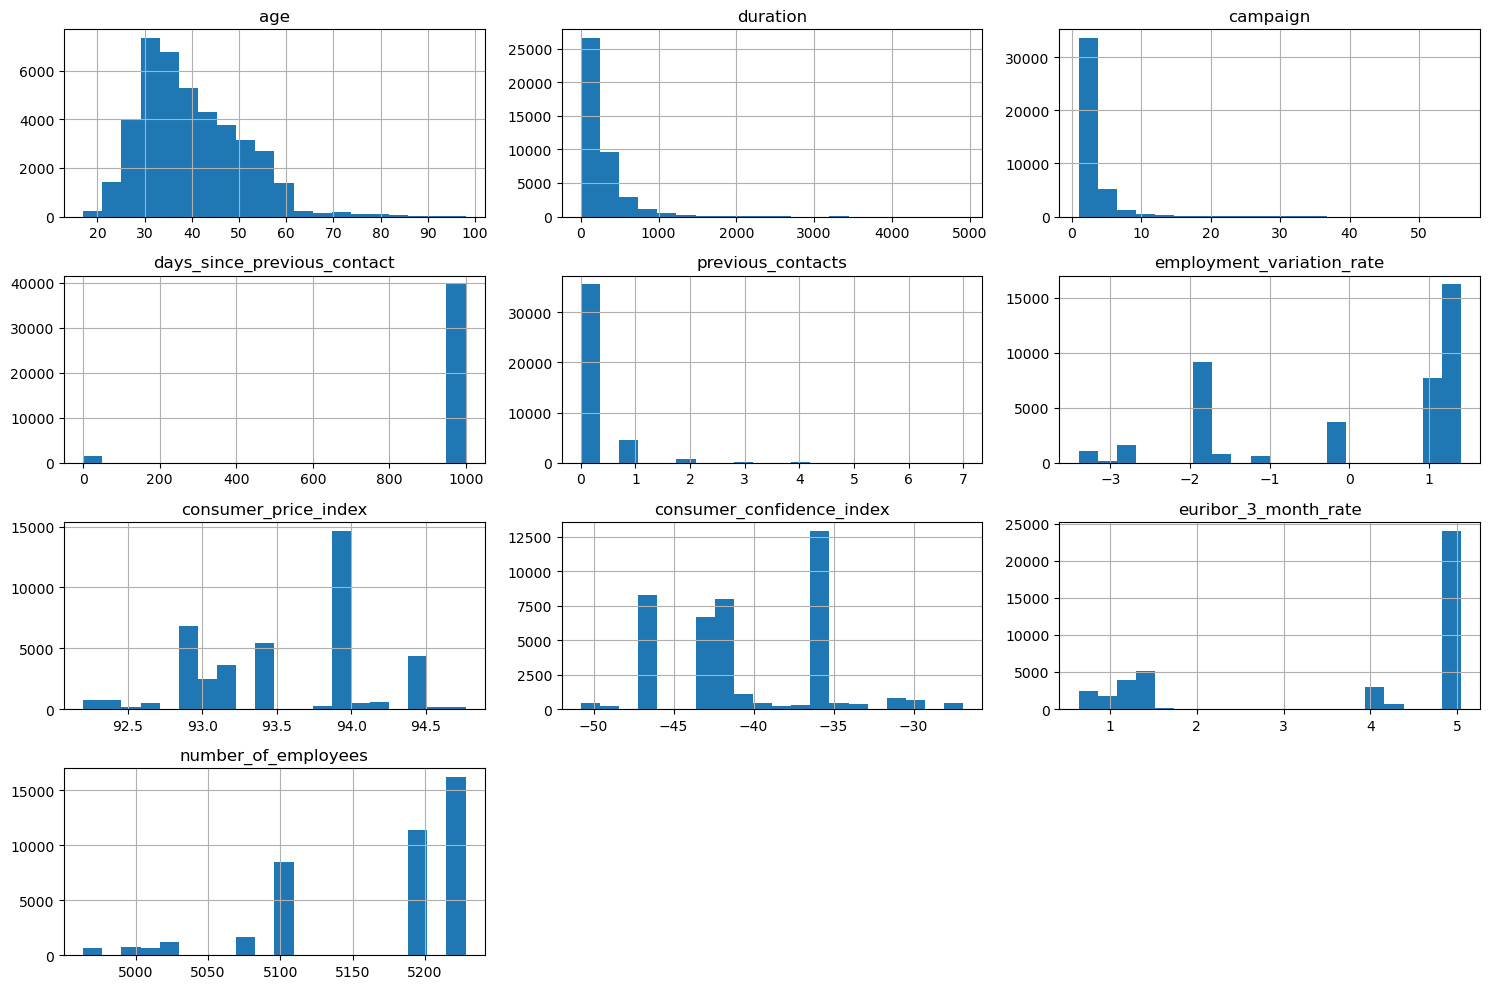

In [12]:
df.hist(figsize=(15, 10), bins=20)
plt.tight_layout()
plt.show()

### Distribution of Categorical Variables

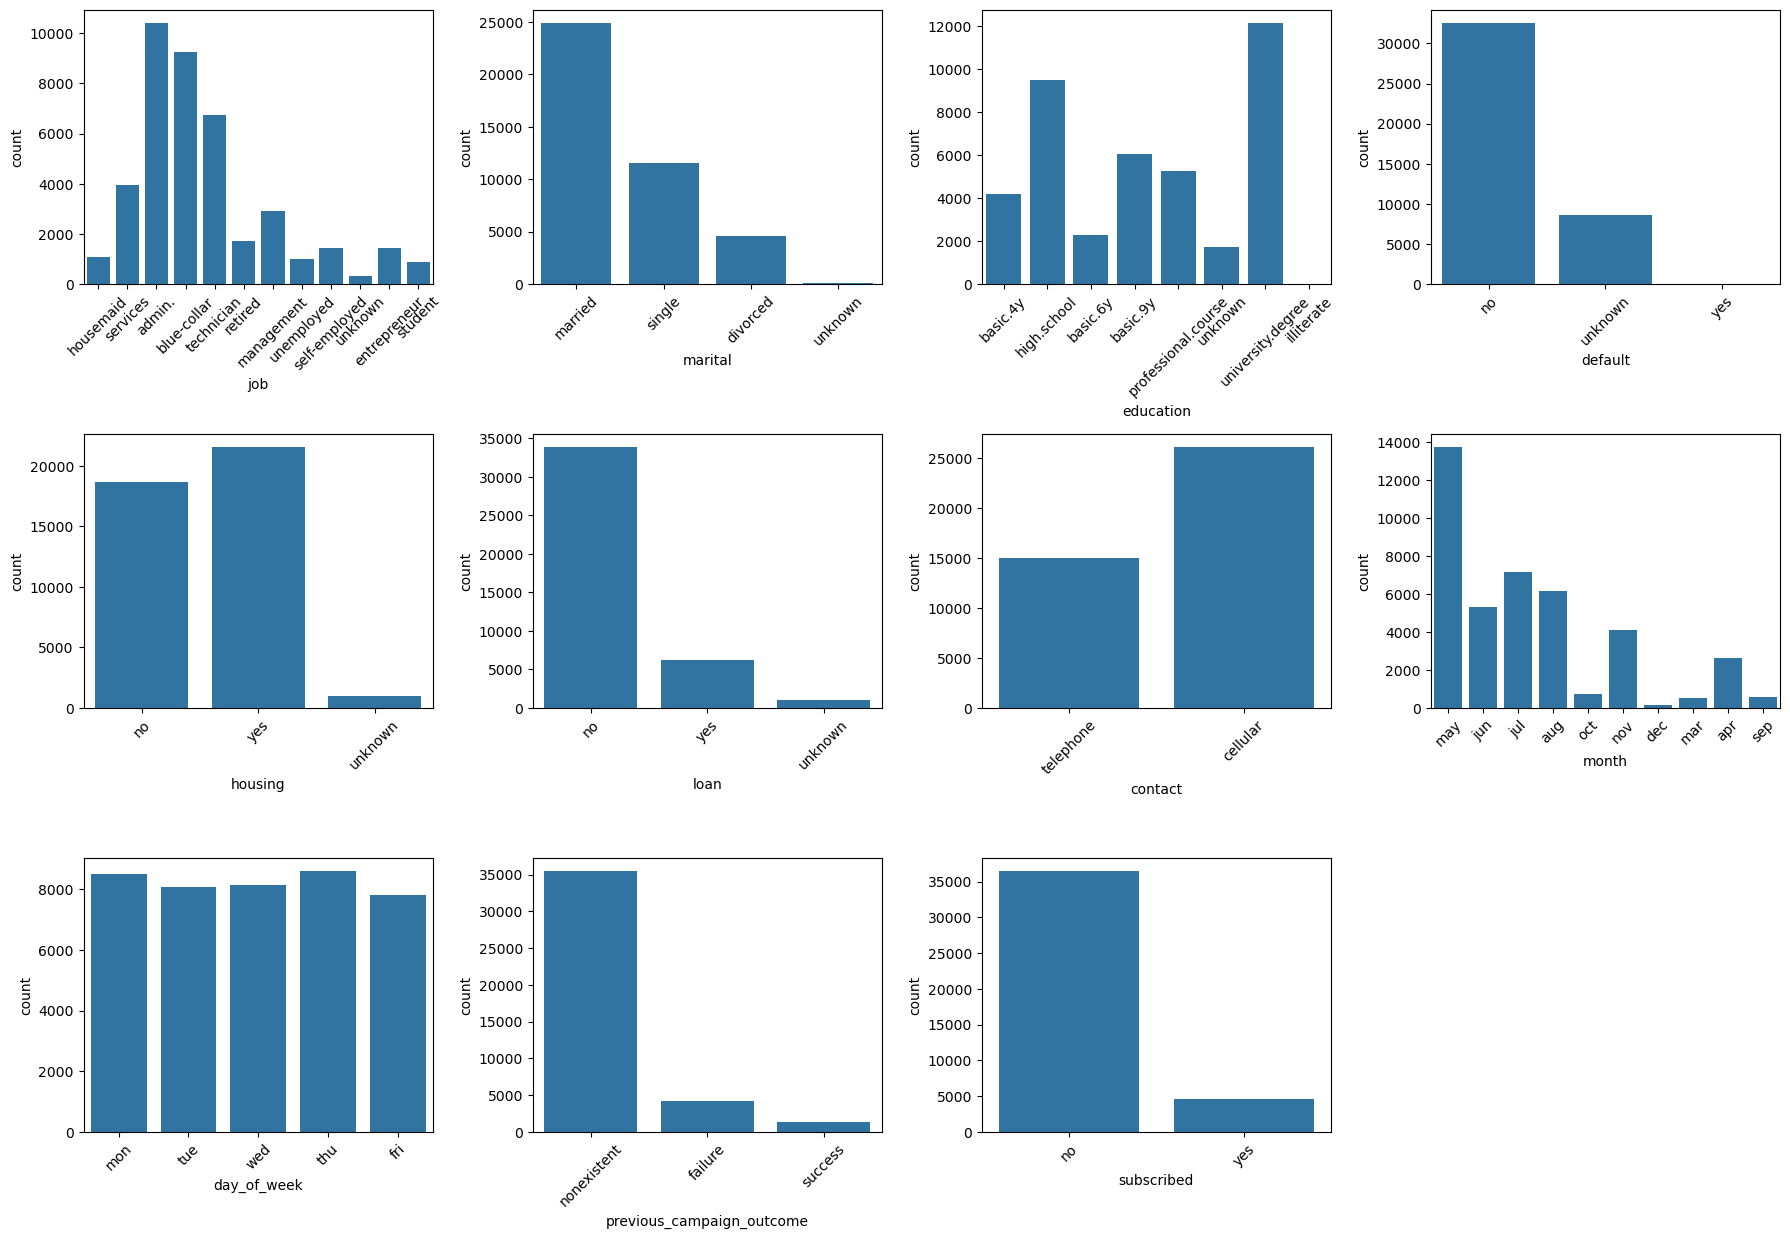

In [13]:
categorical_cols = df.select_dtypes(include='object').columns

plt.figure(figsize=(18, 20))

for i, col in enumerate(categorical_cols, 1):
    plt.subplot(5, 4, i)
    sns.countplot(data=df, x=col)
    plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### Target Variable Distribution

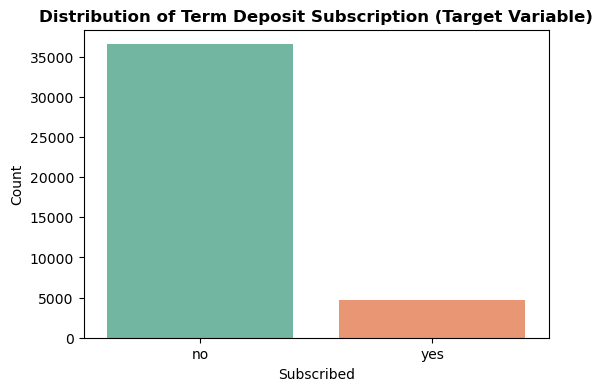

In [14]:
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df, x='subscribed', palette='Set2')
plt.title('Distribution of Term Deposit Subscription (Target Variable)', fontsize=12, fontweight='bold')
plt.xlabel('Subscribed', fontsize=10)
plt.ylabel('Count', fontsize=10)
plt.show()

### Customer Age Distribution

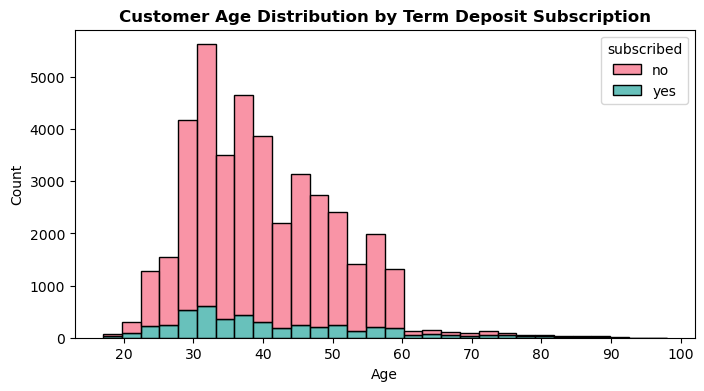

In [15]:
plt.figure(figsize=(8, 4))
sns.histplot(data=df, x='age', hue='subscribed', multiple='stack', palette='husl', bins=30)
plt.title('Customer Age Distribution by Term Deposit Subscription', fontsize=12, fontweight='bold')
plt.xlabel('Age', fontsize=10)
plt.ylabel('Count', fontsize=10)
plt.show()

### Subscription by Job Category

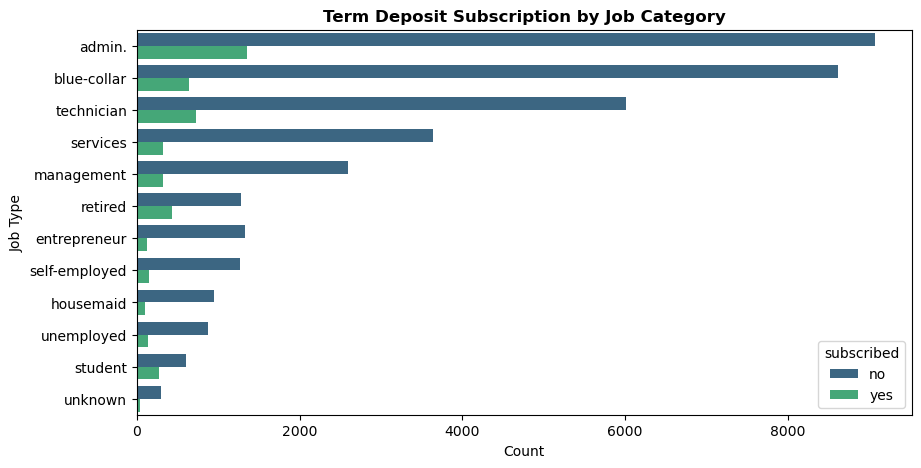

In [16]:
plt.figure(figsize=(10, 5))
job_order = df['job'].value_counts().index
ax = sns.countplot(data=df, y='job', hue='subscribed', order=job_order, palette='viridis')
plt.title('Term Deposit Subscription by Job Category', fontsize=12, fontweight='bold')
plt.xlabel('Count', fontsize=10)
plt.ylabel('Job Type', fontsize=10)
plt.show()

### Subscription by Contact Communication Type

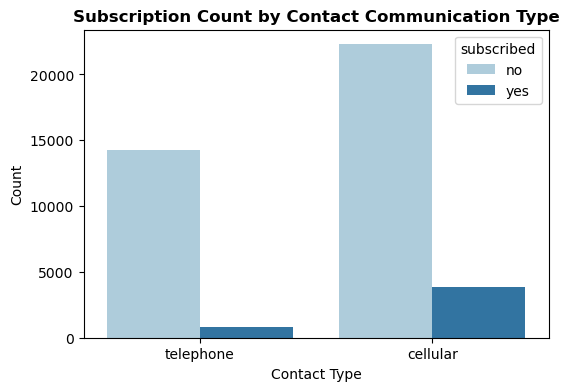

In [17]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='contact', hue='subscribed', palette='Paired')
plt.title('Subscription Count by Contact Communication Type', fontsize=12, fontweight='bold')
plt.xlabel('Contact Type', fontsize=10)
plt.ylabel('Count', fontsize=10)
plt.show()

### Subscription by Contact Month

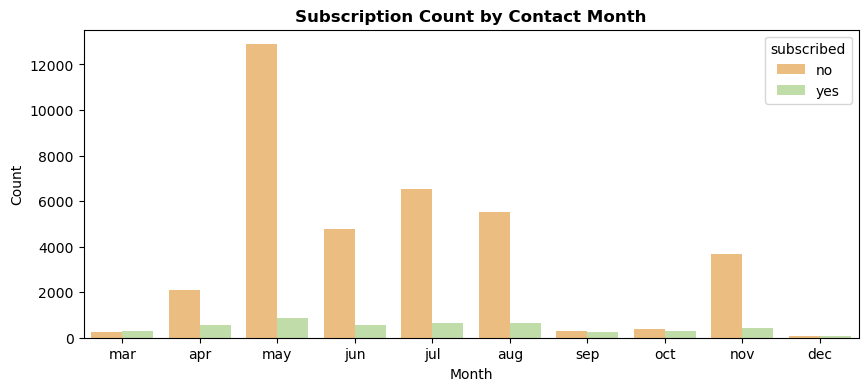

In [18]:
plt.figure(figsize=(10, 4))
month_order = ['mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec']
sns.countplot(data=df, x='month', hue='subscribed', order=month_order, palette='Spectral')
plt.title('Subscription Count by Contact Month', fontsize=12, fontweight='bold')
plt.xlabel('Month', fontsize=10)
plt.ylabel('Count', fontsize=10)
plt.show()

### Interest Rate Distribution

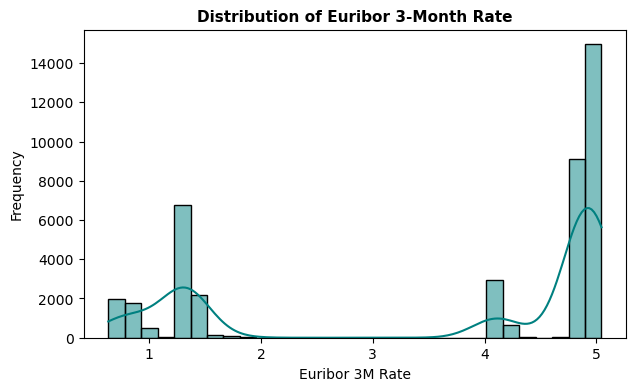

In [19]:
plt.figure(figsize=(7, 4))
sns.histplot(df['euribor_3_month_rate'], kde=True, color='teal', bins=30)
plt.title('Distribution of Euribor 3-Month Rate', fontsize=11, fontweight='bold')
plt.xlabel('Euribor 3M Rate', fontsize=10)
plt.ylabel('Frequency', fontsize=10)
plt.show()

### Customer Education Breakdown

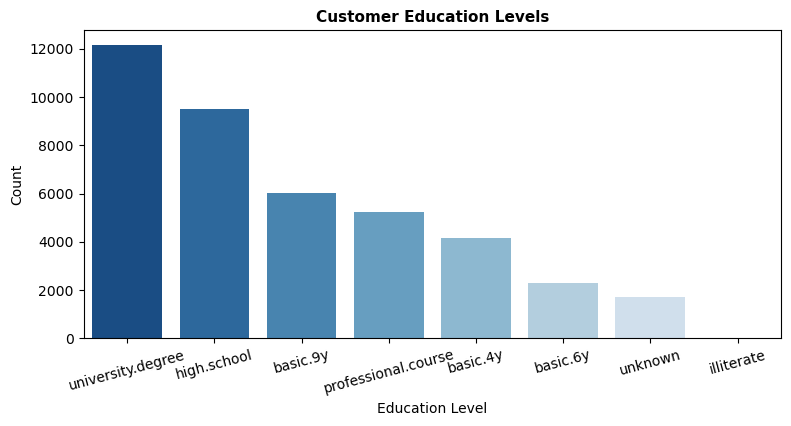

In [20]:
plt.figure(figsize=(9, 4))
ax = sns.countplot(data=df, x='education', order=df['education'].value_counts().index, palette='Blues_r')
plt.title('Customer Education Levels', fontsize=11, fontweight='bold')
plt.xlabel('Education Level', fontsize=10)
plt.ylabel('Count', fontsize=10)
plt.xticks(rotation=15)
plt.show()

### Housing Loan vs. Subscriptions

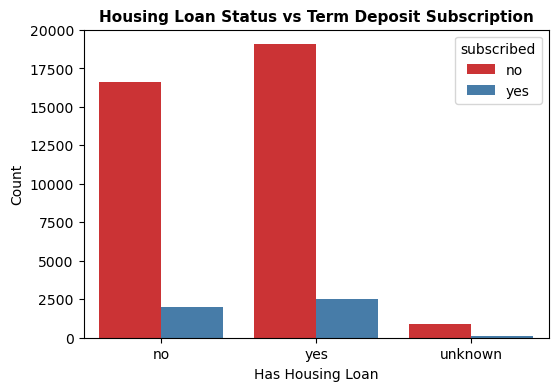

In [21]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='housing', hue='subscribed', palette='Set1')
plt.title('Housing Loan Status vs Term Deposit Subscription', fontsize=11, fontweight='bold')
plt.xlabel('Has Housing Loan', fontsize=10)
plt.ylabel('Count', fontsize=10)
plt.show()

### Call Duration by Job Type & Subcription

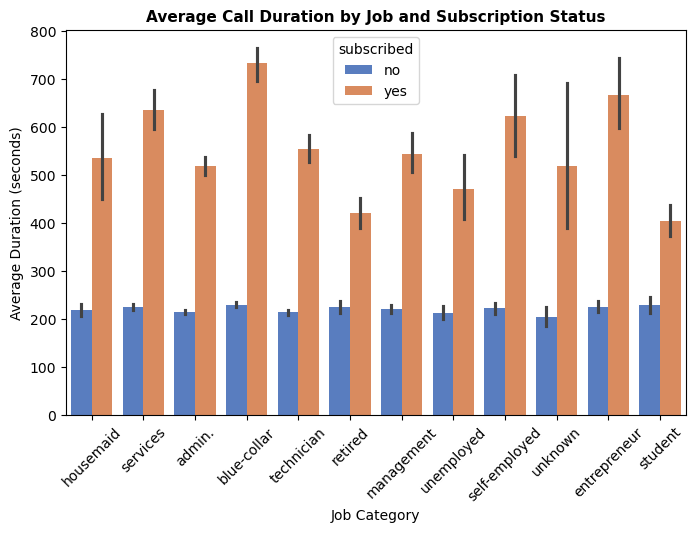

In [22]:
plt.figure(figsize=(8, 5))
sns.barplot(data=df, x='job', y='duration', hue='subscribed', palette='muted')
plt.title('Average Call Duration by Job and Subscription Status', fontsize=11, fontweight='bold')
plt.xlabel('Job Category', fontsize=10)
plt.ylabel('Average Duration (seconds)', fontsize=10)
plt.xticks(rotation=45)
plt.show()

### TRAIN-TEST SPLIT

In [23]:
#Separate features (X) and target (y)
X = df.drop(columns=["subscribed"])
y = df["subscribed"].map({"yes": 1, "no": 0})

#Split into training (80%) and testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Training set shape: (32940, 20)
Testing set shape: (8236, 20)


### Building the Preprocessing Pipeline

In [24]:
# 1. Identify numeric and categorical columns
numeric_cols = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()
categorical_cols = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

# 2. Create the preprocessing pipeline for numbers and text
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_cols),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
            categorical_cols,),])

print("Preprocessor created successfully!")
print(f"Numeric columns: {len(numeric_cols)}")
print(f"Categorical columns: {len(categorical_cols)}")

Preprocessor created successfully!
Numeric columns: 10
Categorical columns: 10


### Training the Logistic Regression Model

In [25]:
# 1. Combine the preprocessor and Logistic Regression into a pipeline
model_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier",LogisticRegression(max_iter=1000, random_state=42),
        ),  # max_iter=1000 gives it enough time to converge
    ])

# 2. Train (fit) the model on the training data
model_pipeline.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [26]:
from sklearn.metrics import accuracy_score, classification_report

# 1. Making predictions on the test set
y_pred = model_pipeline.predict(X_test)

# 2. Calculating accuracy 
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy:.4f}\n")

print("Classification Report:")
print(classification_report(y_test, y_pred))

Model Accuracy: 0.9095

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.97      0.95      7308
           1       0.65      0.42      0.51       928

    accuracy                           0.91      8236
   macro avg       0.79      0.70      0.73      8236
weighted avg       0.90      0.91      0.90      8236



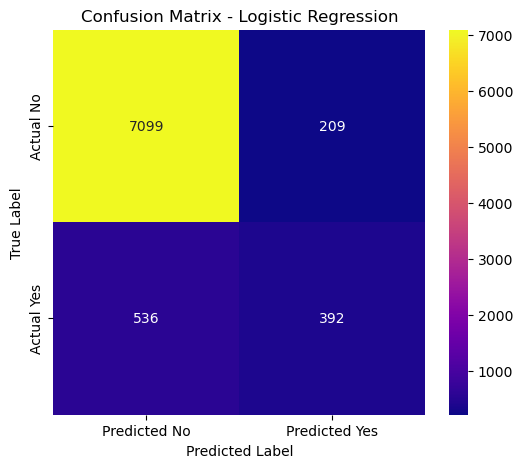

In [27]:
from sklearn.metrics import confusion_matrix

#Calculate the confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    conf_matrix,
    annot=True,
    fmt="d",
    cmap="plasma",
    cbar=True,
    xticklabels=["Predicted No", "Predicted Yes"],
    yticklabels=["Actual No", "Actual Yes"],
)
plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

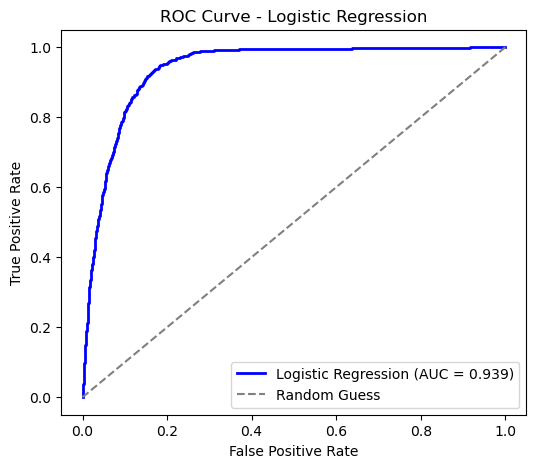

In [28]:
from sklearn.metrics import roc_auc_score, roc_curve
import matplotlib.pyplot as plt

# Get predicted probabilities for the positive class (1)
y_prob = model_pipeline.predict_proba(X_test)[:, 1]

# Calculate False Positive Rate and True Positive Rate
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc_score = roc_auc_score(y_test, y_prob)

# Plot the ROC curve
plt.figure(figsize=(6, 5))
plt.plot(
    fpr,
    tpr,
    color="blue",
    lw=2,
    label=f"Logistic Regression (AUC = {auc_score:.3f})",
)
plt.plot([0, 1], [0, 1], color="gray", linestyle="--", label="Random Guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression")
plt.legend(loc="lower right")
plt.show()

In [29]:
import numpy as np

# 1. Calculate Youden's J statistic (Sensitivity + Specificity - 1)
# This finds the point on the ROC curve furthest from the random guess line
j_scores = tpr - fpr
best_idx = np.argmax(j_scores)
best_threshold = thresholds[best_idx]

print(f"The optimal classification threshold is: {best_threshold:.3f}")

# 2. Apply this new threshold to make predictions
y_pred_custom = (y_prob >= best_threshold).astype(int)

# 3. View the new classification report with this threshold
from sklearn.metrics import classification_report

print("\n--- Classification Report with Optimal Threshold ---")
print(classification_report(y_test, y_pred_custom))

The optimal classification threshold is: 0.099

--- Classification Report with Optimal Threshold ---
              precision    recall  f1-score   support

           0       0.99      0.84      0.91      7308
           1       0.43      0.92      0.58       928

    accuracy                           0.85      8236
   macro avg       0.71      0.88      0.75      8236
weighted avg       0.93      0.85      0.87      8236



### CONCLUSION

#### - By setting the threshold to 0.099, the model successfully catches 92% of the customers who actually say yes, with an overall accuracy of 85%.
#### - This means the bank can use it to target the right people instead of wasting time calling everyone blindly.
#### - Plus, things like longer call lengths and past campaign history proved to be the biggest clues in figuring out who would actually buy.